#ต่อ google drive

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
T2_ROOT = "/content/drive/MyDrive/Image_Project/Dataset/T2"

T2_GAMMA20 = f"{T2_ROOT}/gamma_2.0/images"

In [5]:
import os

print("Folder exists:", os.path.exists(T2_GAMMA20))

files = [
    f for f in os.listdir(T2_GAMMA20)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Images:", len(files))

Folder exists: True
Images: 246


#ทดลองการใช้ ClAHE

In [6]:
import cv2

def apply_clahe(img_bgr, clip_limit=2.0, tile_grid=(8, 8)):

    # BGR -> LAB
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

    # แยก L, A, B
    l, a, b = cv2.split(lab)

    # สร้าง CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid
    )

    # CLAHE เฉพาะ L channel
    l_eq = clahe.apply(l)

    # รวม channel กลับ
    lab_eq = cv2.merge((l_eq, a, b))

    # LAB -> BGR
    result = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)

    return result

In [7]:
import matplotlib.pyplot as plt

sample_file = files[0]

image_path = os.path.join(T2_GAMMA20, sample_file)

dark_img = cv2.imread(image_path)

clahe_img = apply_clahe(
    dark_img,
    clip_limit=2.0,
    tile_grid=(8, 8)
)

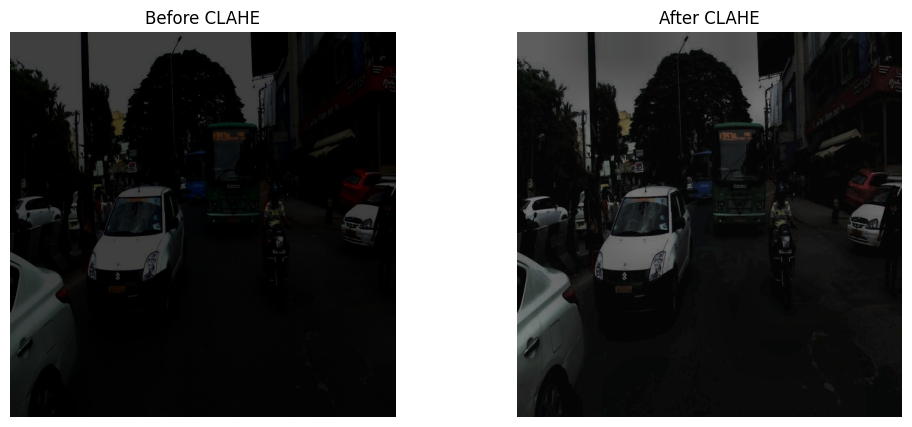

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("Before CLAHE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(clahe_img, cv2.COLOR_BGR2RGB))
plt.title("After CLAHE")
plt.axis("off")

plt.show()

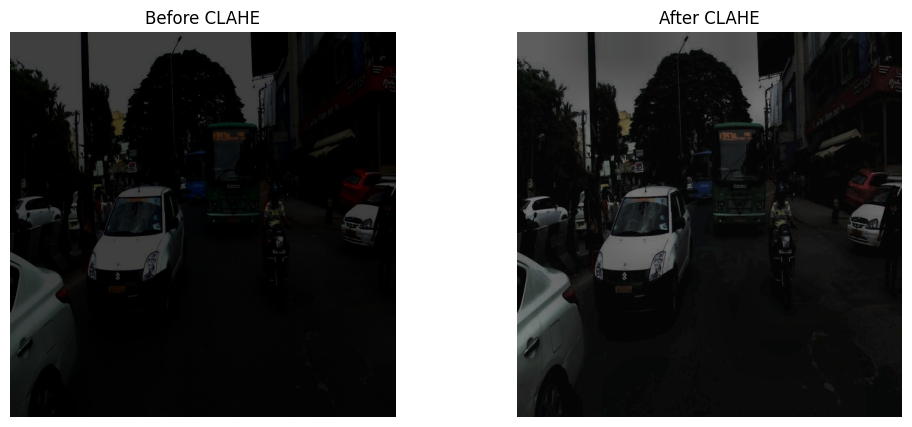

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("Before CLAHE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(clahe_img, cv2.COLOR_BGR2RGB))
plt.title("After CLAHE")
plt.axis("off")

# 1. บันทึกรูปภาพ (กำหนดความละเอียดได้ด้วย dpi)
plt.savefig("clahe_comparison.png", bbox_inches='tight', dpi=300)

# 2. แสดงผลบนหน้าจอ
plt.show()

**เปรียบเทียบกับ original**

In [ ]:
T1_IMAGE_DIR = "/content/drive/MyDrive/Image_Project/Dataset/T1/images"

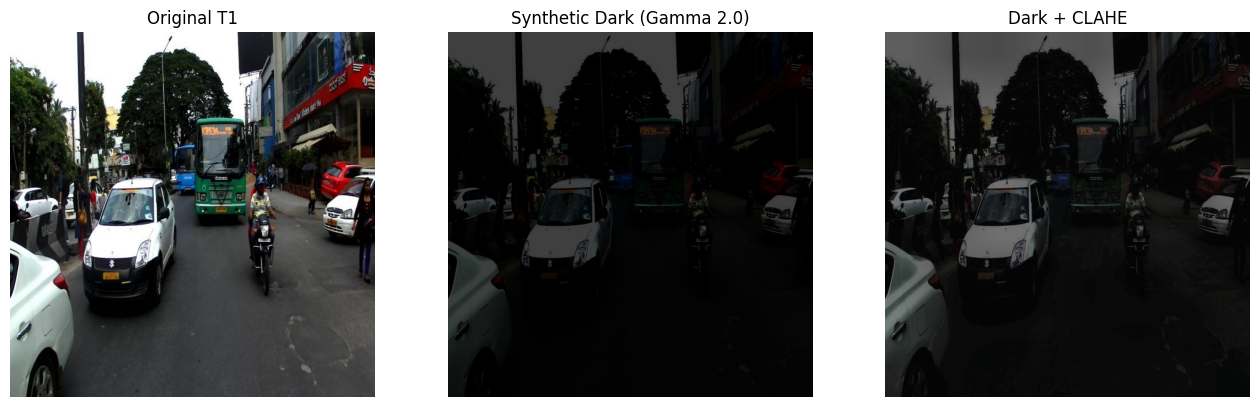

In [ ]:
original_img = cv2.imread(
    os.path.join(T1_IMAGE_DIR, sample_file)
)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Original T1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("Synthetic Dark (Gamma 2.0)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(clahe_img, cv2.COLOR_BGR2RGB))
plt.title("Dark + CLAHE")
plt.axis("off")

plt.show()

#**ทดลอง CLAHE หลายค่า**

**ทดลอง Cliplimit**

In [9]:
settings = [
    (1.0, (8, 8)),
    (2.0, (8, 8)),
    (4.0, (8, 8))
]
# clipLimit ต่ำ
#enhancement อ่อน

#clipLimit สูง
#contrast แรงขึ้น
#แต่ noise อาจแรงขึ้นด้วย

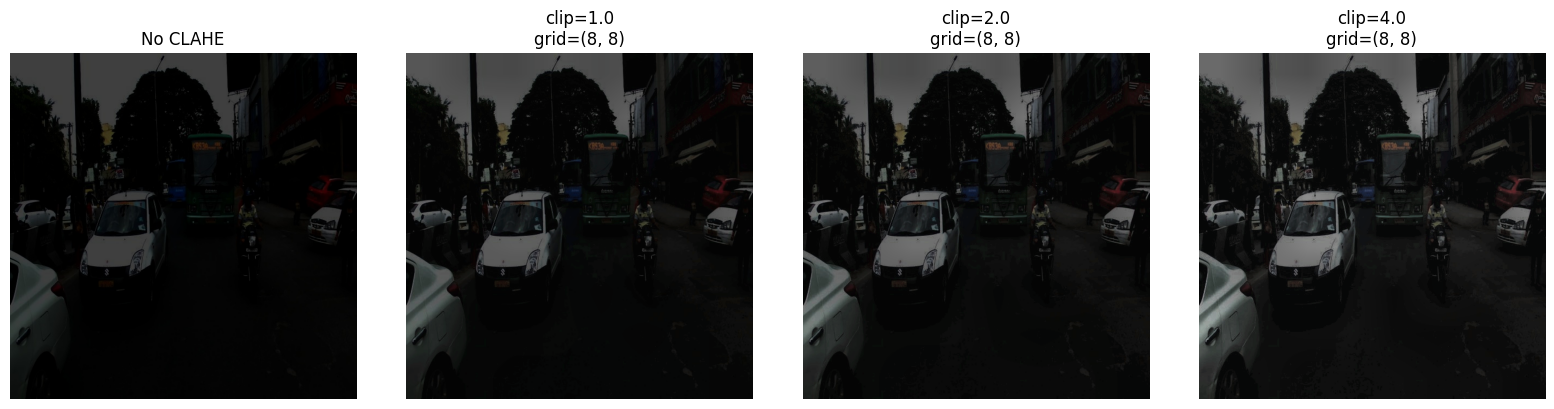

In [10]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("No CLAHE")
plt.axis("off")

for i, (clip, grid) in enumerate(settings, start=2):

    result = apply_clahe(
        dark_img,
        clip_limit=clip,
        tile_grid=grid
    )

    plt.subplot(1, 4, i)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"clip={clip}\ngrid={grid}")
    plt.axis("off")

plt.tight_layout()
plt.show()

**ทดลอง tileGridSize**

In [11]:
grid_settings = [
    (4, 4),
    (8, 8),
    (16, 16)
]

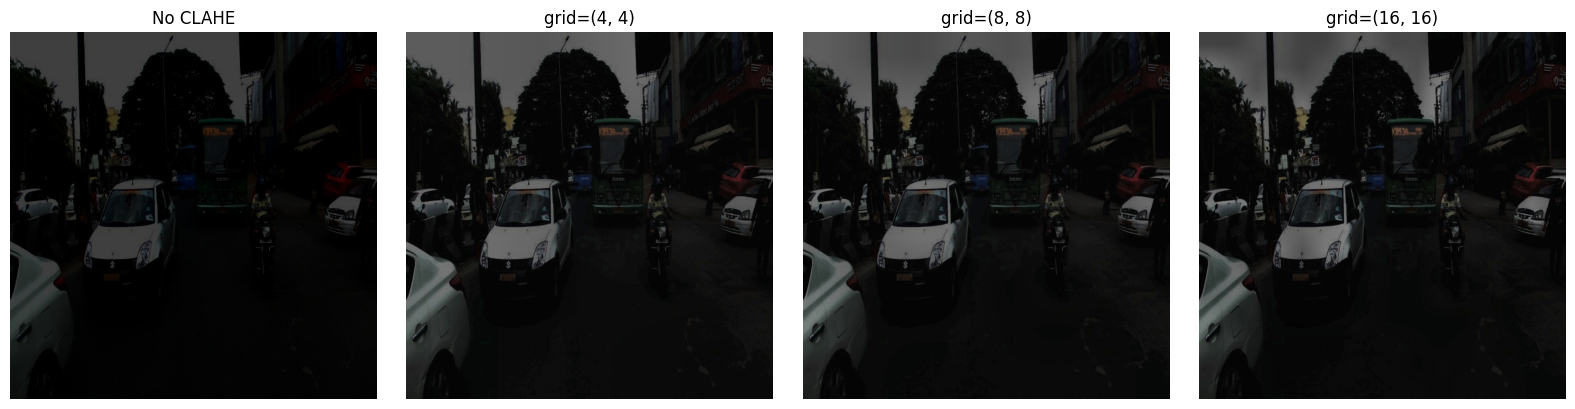

In [12]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("No CLAHE")
plt.axis("off")

for i, grid in enumerate(grid_settings, start=2):

    result = apply_clahe(
        dark_img,
        clip_limit=2.0,
        tile_grid=grid
    )

    plt.subplot(1, 4, i)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"grid={grid}")
    plt.axis("off")

plt.tight_layout()
plt.show()

#นำ CLAHE ไปทดลองกับ T1 , T2 , T3

In [ ]:
CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)

In [ ]:
import cv2

def apply_clahe(img_bgr, clip_limit=2.0, tile_grid=(8, 8)):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid
    )

    l_eq = clahe.apply(l)

    result_lab = cv2.merge((l_eq, a, b))

    result_bgr = cv2.cvtColor(
        result_lab,
        cv2.COLOR_LAB2BGR
    )

    return result_bgr

In [ ]:
CLAHE_ROOT = "/content/drive/MyDrive/Image_Project/Dataset/CLAHE"

In [ ]:
import os

output_folders = [
    "T1/images",
    "T2_gamma_1.5/images",
    "T2_gamma_2.0/images",
    "T2_gamma_2.5/images"
]

for folder in output_folders:
    os.makedirs(
        os.path.join(CLAHE_ROOT, folder),
        exist_ok=True
    )

print("Folders created")

Folders created


In [ ]:
from tqdm import tqdm
import os
import cv2

def process_folder_with_clahe(
    input_dir,
    output_dir,
    clip_limit=2.0,
    tile_grid=(8, 8)
):

    os.makedirs(output_dir, exist_ok=True)

    files = [
        f for f in os.listdir(input_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    for filename in tqdm(files):

        input_path = os.path.join(
            input_dir,
            filename
        )

        output_path = os.path.join(
            output_dir,
            filename
        )

        img = cv2.imread(input_path)

        if img is None:
            print("Cannot read:", filename)
            continue

        result = apply_clahe(
            img,
            clip_limit=clip_limit,
            tile_grid=tile_grid
        )

        cv2.imwrite(
            output_path,
            result
        )

    print(
        "Finished:",
        len(files),
        "images"
    )

In [ ]:
T1_IMAGE_DIR = "/content/drive/MyDrive/Image_Project/Dataset/T1/images"

In [ ]:
CLAHE_T1 = f"{CLAHE_ROOT}/T1/images"

In [ ]:
process_folder_with_clahe(
    T1_IMAGE_DIR,
    CLAHE_T1,
    clip_limit=CLAHE_CLIP,
    tile_grid=CLAHE_GRID
)

100%|██████████| 246/246 [00:21<00:00, 11.34it/s]

Finished: 246 images


In [ ]:
T2_GAMMA15 = "/content/drive/MyDrive/Image_Project/Dataset/T2/gamma_1.5/images"

CLAHE_T2_GAMMA15 = f"{CLAHE_ROOT}/T2_gamma_1.5/images"

process_folder_with_clahe(
    T2_GAMMA15,
    CLAHE_T2_GAMMA15,
    clip_limit=CLAHE_CLIP,
    tile_grid=CLAHE_GRID
)

100%|██████████| 246/246 [00:13<00:00, 17.63it/s]

Finished: 246 images


In [ ]:
T2_GAMMA20 = "/content/drive/MyDrive/Image_Project/Dataset/T2/gamma_2.0/images"

CLAHE_T2_GAMMA20 = f"{CLAHE_ROOT}/T2_gamma_2.0/images"

process_folder_with_clahe(
    T2_GAMMA20,
    CLAHE_T2_GAMMA20,
    clip_limit=CLAHE_CLIP,
    tile_grid=CLAHE_GRID
)

100%|██████████| 246/246 [00:18<00:00, 13.12it/s]

Finished: 246 images


In [ ]:
T2_GAMMA25 = "/content/drive/MyDrive/Image_Project/Dataset/T2/gamma_2.5/images"

CLAHE_T2_GAMMA25 = f"{CLAHE_ROOT}/T2_gamma_2.5/images"

process_folder_with_clahe(
    T2_GAMMA25,
    CLAHE_T2_GAMMA25,
    clip_limit=CLAHE_CLIP,
    tile_grid=CLAHE_GRID
)

100%|██████████| 246/246 [00:12<00:00, 19.29it/s]

Finished: 246 images


In [ ]:
T3_IMAGE_DIR = "/content/drive/MyDrive/Image_Project/Dataset/T3/images"

CLAHE_T3 = f"{CLAHE_ROOT}/T3/images"

process_folder_with_clahe(
    T3_IMAGE_DIR,
    CLAHE_T3,
    clip_limit=CLAHE_CLIP,
    tile_grid=CLAHE_GRID
)

100%|██████████| 560/560 [01:35<00:00,  5.86it/s]

Finished: 560 images


สร้าง Label ด้วย


In [ ]:
import shutil

source_labels = "/content/drive/MyDrive/Image_Project/Dataset/T1/labels"

destination_labels = f"{CLAHE_ROOT}/T1/labels"

if os.path.exists(destination_labels):
    shutil.rmtree(destination_labels)

shutil.copytree(
    source_labels,
    destination_labels
)

print("Labels copied")

Labels copied


In [ ]:
import shutil

source_labels = "/content/drive/MyDrive/Image_Project/Dataset/T2/gamma_1.5/labels"

destination_labels = f"{CLAHE_ROOT}/T2_gamma_1.5/labels"

if os.path.exists(destination_labels):
    shutil.rmtree(destination_labels)

shutil.copytree(
    source_labels,
    destination_labels
)

print("Labels copied")

Labels copied


In [ ]:
import shutil

source_labels = "/content/drive/MyDrive/Image_Project/Dataset/T2/gamma_2.0/labels"

destination_labels = f"{CLAHE_ROOT}/T2_gamma_2.0/labels"

if os.path.exists(destination_labels):
    shutil.rmtree(destination_labels)

shutil.copytree(
    source_labels,
    destination_labels
)

print("Labels copied")

Labels copied


In [ ]:
import shutil

source_labels = "/content/drive/MyDrive/Image_Project/Dataset/T2/gamma_2.5/labels"

destination_labels = f"{CLAHE_ROOT}/T2_gamma_2.5/labels"

if os.path.exists(destination_labels):
    shutil.rmtree(destination_labels)

shutil.copytree(
    source_labels,
    destination_labels
)

print("Labels copied")

Labels copied


In [ ]:
import shutil

source_labels = "/content/drive/MyDrive/Image_Project/Dataset/T3/labels"

destination_labels = f"{CLAHE_ROOT}/T3/labels"

if os.path.exists(destination_labels):
    shutil.rmtree(destination_labels)

shutil.copytree(
    source_labels,
    destination_labels
)

print("Labels copied")

Labels copied


# เช็ค ภาพ

In [ ]:
import random
import matplotlib.pyplot as plt

samples = random.sample(
    os.listdir(T2_GAMMA20),
    5
)

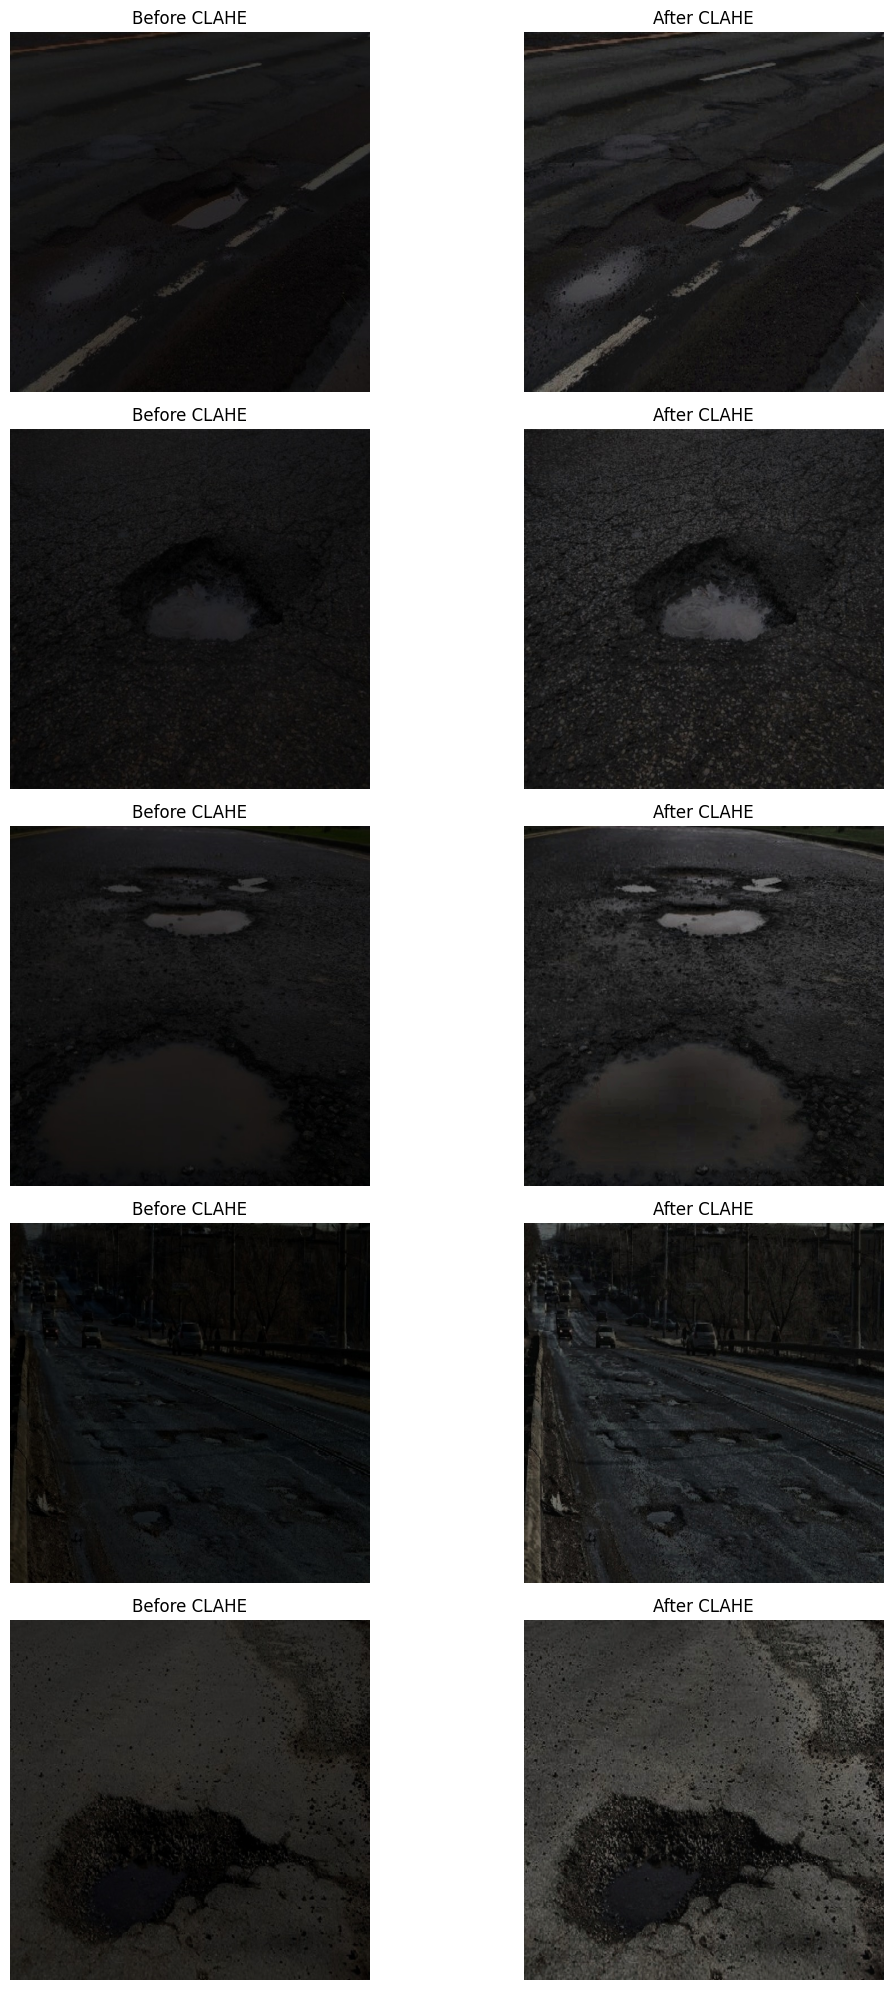

In [ ]:
plt.figure(figsize=(12, 20))

for i, filename in enumerate(samples):

    before = cv2.imread(
        os.path.join(
            T2_GAMMA20,
            filename
        )
    )

    after = cv2.imread(
        os.path.join(
            CLAHE_T2_GAMMA20,
            filename
        )
    )

    plt.subplot(5, 2, i*2 + 1)

    plt.imshow(
        cv2.cvtColor(
            before,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title("Before CLAHE")
    plt.axis("off")

    plt.subplot(5, 2, i*2 + 2)

    plt.imshow(
        cv2.cvtColor(
            after,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title("After CLAHE")
    plt.axis("off")

plt.tight_layout()
plt.show()

สร้าง YML

In [ ]:
import yaml
import os

ORIGINAL_YAML = "/content/drive/MyDrive/Image_Project/Dataset/T1/data.yaml"

with open(ORIGINAL_YAML, "r") as f:
    original = yaml.safe_load(f)

class_names = original["names"]

print(class_names)

['Drain Hole', 'Pothole', 'Sewer Cover']


In [ ]:
datasets = {
    "T1": f"{CLAHE_ROOT}/T1",
    "T2_gamma_1.5": f"{CLAHE_ROOT}/T2_gamma_1.5",
    "T2_gamma_2.0": f"{CLAHE_ROOT}/T2_gamma_2.0",
    "T2_gamma_2.5": f"{CLAHE_ROOT}/T2_gamma_2.5",
}

for name, root in datasets.items():

    data = {
        "path": root,
        "train": "images",
        "val": "images",
        "test": "images",
        "names": class_names
    }

    yaml_path = os.path.join(root, "data.yaml")

    with open(yaml_path, "w") as f:
        yaml.dump(
            data,
            f,
            sort_keys=False,
            allow_unicode=True
        )

    print("Created:", yaml_path)

Created: /content/drive/MyDrive/Image_Project/Dataset/CLAHE/T1/data.yaml
Created: /content/drive/MyDrive/Image_Project/Dataset/CLAHE/T2_gamma_1.5/data.yaml
Created: /content/drive/MyDrive/Image_Project/Dataset/CLAHE/T2_gamma_2.0/data.yaml
Created: /content/drive/MyDrive/Image_Project/Dataset/CLAHE/T2_gamma_2.5/data.yaml
